# Create and Save Cutouts


In [36]:
from astrocut import get_center_pixel, ASDFCutout
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord

import os

import pandas as pd
import astrocut
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from datetime import datetime

from tqdm import trange

In [12]:
def create_image_cutout_test(asdf_file_uri, cutout_size, position, display_cut = False, display_full=False, full_data = [None,None]):
    """
    Creates an image cutout using ASDF cutout (imcut)
    """


    ra, dec = position[0],position[1]
    center_coord = SkyCoord(ra, dec, unit='deg')
    
    
    
    
    if display_full == True:
        r_x, r_y = wcs_.wcs_world2pix(ra_, dec_, 1)
        data, wcs = full_data[0], full_data[1]
        rect = Rectangle((r_x-(cutout_size[0]/2), r_y-(cutout_size[1]/2)), (cutout_size[0]), (cutout_size[1]), linewidth=1, edgecolor='r', facecolor='none')
        plt.figure(figsize=(10, 8))
        ax2 = plt.subplot(projection=wcs)
        plt.imshow(data, vmin=0, vmax=5, origin='lower')
        # plt.scatter(pixels[0], pixels[1], marker='*', color='red')
        ax2.scatter(ra, dec, marker='o', facecolor='none', edgecolor='red', transform=ax2.get_transform('world'))
        ax2.add_patch(rect)
        plt.show()

    # Create the image cutout
    asdf_cutout = ASDFCutout(asdf_file_uri, center_coord, cutout_size, fill_value=0)
    
    # Check the cutout shape and position
    print(f'len of asdf_cutout.cutouts = {len(asdf_cutout.cutouts)}')
    cutout = asdf_cutout.cutouts
    gwcs_asdf = cutout[0].wcs
    
    
    scales = proj_plane_pixel_scales(gwcs_asdf) * 3600  # arcsec/pixel
    
    # x_pix = scales[0]
    # y_pix = scales[1]
    
    print('Cutout Data Shape:', cutout[0].shape)
    print('Cutout Original Position:', cutout[0].position_original)
    print('Cutout Position:', cutout[0].position_cutout)

    if display_cut == True:
        print('Displaying three-filter cutouts of target')
        for i in range(len(cutout)):
            plt.figure()
            ax2 = plt.subplot(projection=gwcs_asdf)
            plt.imshow(cutout[i].data, vmin=0, vmax=5, origin='lower')
            plt.show()

    return cutout, scales

def MTF_on_normalised_data(x, m):
    """
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    Compute the Midtones Transfer Function (MTF) for given x and m.
    This is basically a way to attempt to automatically set the "curves" tool from e.g. photoshop, 
    where m sets the curve and MTF is the application of the curve.

    Documented by K. Sanderson, 2026. 
    
    Parameters:
    -----------
    x: nd.array
        image data normalized by (data-min)/(max-min) of image
    m: float
        determines which values of x get mapped to the midpoint 
        (MTF(x)=0.5). If x=m, MTF=0.5. 
        - if m = 0.5, the midpoint of the normalized data is mapped 
          to the MTF midpoint (no change)
        - if m < 0.5, fainter pixel values are brightened since they 
          are mapped to MTF=0.5
        - if m> 0.5, brighter pixels are darkened since they are 
          mapped to MTF=0.5
    """
    # x = np.clip(x, 0, 1)
    assert x.max() <= 1
    assert x.min() >= 0
    y = np.zeros_like(x)
    mask0 = (x == 0)
    maskm = (x == m)
    mask1 = (x == 1)
    mask_else = ~(mask0 | maskm | mask1)
    # these remain fixed
    y[mask0] = 0
    y[maskm] = 0.5
    y[mask1] = 1
    # ..and everything else gets curved
    x_else = x[mask_else]

    # shape of the curve
    numerator = (m - 1) * x_else
    denominator = (2 * m - 1) * x_else - m
    # apply the curve
    y[mask_else] = numerator / denominator
    return y # curved values
    
def find_m_for_mean(normalized_data, desired_mean, central_crop_size=100, central_crop_fraction=None, quick_mask=False):  # 0.1 arcsec per pixel for MER tiles
    """
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)

    Documented by K. Sanderson, 2026. 
    
    Inverts the equation for MTF(x) to determine which value 
    of m will produce MTF = desired mean given the input data's 
    true mean.

    Parameters:
    ----------
    normalized_data: nd.array
       image data normalized by (data-min)/(max-min) of image
    desired_mean: float
        desired value of MTF produced by the input data's true mean
    central_crop_size: int
        size of box around center of the image to use for the calculation. 
        If central_crop_fraction is not None, central_crop_size is ignored
    central_crop_fraction: float
        fractional size of box around center of the image to use for the calculation. 
        If central_crop_fraction is not None, central_crop_size is ignored
    quick_mask: Boolean
        not implemented here...

    Return:
    ----------
    m value for input into MTF(x) function
    
    """
    
    width = normalized_data.shape[1]
    
    if quick_mask:
        normalized_data_selected = make_quick_mask(normalized_data)
    else:
        if central_crop_fraction is not None:
            central_crop_size = int(central_crop_fraction * width)

        central_crop_low_edge = width//2 - central_crop_size//2
        central_crop_high_edge = width//2 + central_crop_size//2
        normalized_data_selected = normalized_data[central_crop_low_edge:central_crop_high_edge, central_crop_low_edge:central_crop_high_edge]

    # print(normalized_data_selected.sum(), normalized_data_selected.mean())

    x = np.mean(normalized_data_selected)
    alpha = desired_mean
    return (x-alpha*x)/(x-2*alpha*x+alpha)

def apply_MTF(image_data, desired_mean_normalized=0.2, central_crop_size=100, central_crop_fraction=None, quick_mask=False, percentile=99.5):  
    """
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)

    Documented by K. Sanderson, 2026. 
    
    Normalize data, determine appropriate midtones balance parameter m, and 
    apply the Midtones Transfer Function (MTF) for given input image data.

    Parameters:
    ----------
    image_data: nd.array
        image that should be scaled according to the MTF
    desired_mean_normalized: float
        desired value of MTF produced by the input data's true mean
    central_crop_size: int
        size of box around center of the image to use for the calculation. 
        If central_crop_fraction is not None, central_crop_size is ignored
    central_crop_fraction: float
        fractional size of box around center of the image to use for the calculation. 
        If central_crop_fraction is not None, central_crop_size is ignored
    quick_mask: Boolean
        not implemented here...
    percentile: float
        percentile to clip image at before normalizing by (data-min)/(max-min) of image

    Return:
    ----------
    transformed_image_data: nd.array
        input image_data scaled according to the MTF, and then rescaled to 0-255 integer range
        
    """
    image_data = np.nan_to_num(image_data, nan=0.0, posinf=0.0, neginf=0.0)
    
    if percentile is not None:
            image_data = np.clip(image_data, image_data.min(), np.percentile(image_data, percentile))
    
    # Normalize the image data to [0, 1]
    normalized_data = image_data.astype(np.float64)
    min_val = np.min(normalized_data)
    max_val = np.max(normalized_data)
    normalized_data = (normalized_data - min_val) / (max_val - min_val)
    # Desired mean value at 1/5 of the maximum pixel value
    # Raised from 1/8 default from Tian
    # Find the appropriate midtones balance parameter m
    m = find_m_for_mean(normalized_data, desired_mean_normalized, central_crop_size, central_crop_fraction, quick_mask)
    # Apply the MTF to the image
    transformed_data = MTF_on_normalised_data(normalized_data, m)
    # Scale transformed data to [0, 255] for JPEG output
    transformed_image_data = (transformed_data * 255).astype(np.uint8)
    return transformed_image_data
    
def make_mtf_rgb(f1, f2, f3, weights = {}, means=[0.27, 0.25, 0.23, 0.25]):  # last not used
    """
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)

    Documented by K. Sanderson, 2026. 
    
    Apply the MTF to the three input images (filters) and combine images into a 3d array

    Parameters:
    ----------
    f1, f2, f3: nd.array
        input images to be scaled and combined for RGB image creation
    weights: float
        weights to apply to each individual filter image for creating 
        red, green, and blue output images
    means: list of floats
        desired value of MTF produced by the input data's true mean. 
        Should have one for each input filter image

    Return:
    ----------
    stacked 3d array of MTF scaled input images
    """
    mtf_args = {'central_crop_fraction': 1., 'percentile': 99.85}
    f1_mtf = apply_MTF(f1, **mtf_args, desired_mean_normalized=means[0])
    f2_mtf = apply_MTF(f2, **mtf_args, desired_mean_normalized=means[1])
    f3_mtf = apply_MTF(f3, **mtf_args, desired_mean_normalized=means[2])
    # print(f1_mtf, f2_mtf, f3_mtf)
    #weights = jeyhan_color_weights
    #weights = minimal_color_weights
    #weights = klm_color_weights
    
    # if not weights: #if you don't specify weights, use original default weights sent by Jeyhan
    #     weights = dict(
    #         f115w = (0, 0, 1), 
    #         f150w = (0, 0.3, 0.7),
    #         f277w = (0.7, 0.3, 0),
    #         f444w = (1, 0, 0)
    #     )

    red = f1_mtf
    # f115_mtf*weights['f115w'][0] + f150_mtf*weights['f150w'][0] + f277_mtf*weights['f277w'][0] + f444_mtf*weights['f444w'][0]
    green = f2_mtf
    # f115_mtf*weights['f115w'][1] + f150_mtf*weights['f150w'][1] + f277_mtf*weights['f277w'][1] + f444_mtf*weights['f444w'][1]
    blue = f3_mtf
    # f115_mtf*weights['f115w'][2] + f150_mtf*weights['f150w'][2] + f277_mtf*weights['f277w'][2] + f444_mtf*weights['f444w'][2]
    
    return np.stack([red, green, blue], axis=2)

def adjust_dynamic_range(flux, q=100, clip=99.85):
    '''
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    from https://github.com/mwalmsley/bulk-euclid-cutouts/blob/main/bulk_euclid/utils/morphology_utils_ou_mer.py

    Documented by K. Sanderson, 2026. 
    
    Apply arcsinh scaling (Lupton+2004) of image for RGB image creation.
    Lupton+2004: https://iopscience.iop.org/article/10.1086/382245/pdf 

    Parameters:
    ----------
    flux: nd.array
        the input image to apply arcsinh scaling to
    q: float
        determines the point at which arcsinh(x) changes from linear (arcsinh(x)~x for x <<1) 
        to logarithmic (arcsinh(x)~ln(2x) for x>>1). If in linear regime, the pixel values 
        are basically preserved. 
    clip: float
        the upper percentile at which to clip the scaled image data to before returning
    
    
    Return:
    ----------
    im: nd.array
        scaled, clipped image data
    '''
    im = np.arcsinh(flux * q)

    if clip < 100:
        im = np.clip(im, 0, np.nanpercentile(im, clip))

    return  im

def to_uint8(im, clip_below_zero=True):
    '''
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    from https://github.com/mwalmsley/bulk-euclid-cutouts/blob/main/bulk_euclid/utils/morphology_utils_ou_mer.py
    
    Documented by K. Sanderson, 2026. 

    Scale pixel values to lie between 0-255

    Parameters:
    ----------
    im: nd.array
        the image to be scaled to 0-255
    clip_below_zero: boolean
        Clip so that 0 is the minimum pixel value. If False, the 
        "normalization" below may result in negative pixel values.
        
    Return:
    ----------
    image with pixel values between 0-255
    '''

    if clip_below_zero:
        im = np.clip(im, 0, None)
    im_min = np.nanmin(im.astype(float))
    im_max = np.nanmax(im.astype(float))
    assert im_min < im_max, f'Image min {im_min} >= max {im_max}, likely all data is zero or NAN i.e. missing'
    im = (im + im_min) / (im_min + im_max) # why do the normalization in this way if clip_below_zero is optional?
    return (255 * im).astype(np.uint8)
    
def make_vis_only_cutout(vis_cutout, q=100, clip=99.85):
    '''
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    from https://github.com/mwalmsley/bulk-euclid-cutouts/blob/main/bulk_euclid/utils/morphology_utils_ou_mer.py

    Documented by K. Sanderson, 2026.
    
    Apply arcsinh scaling (adjust_dynamic_range) and rescale pixel values to lie between 0 and 255.

    Parameters:
    ----------
    vis_cutout: nd.array
        raw image cutout to be scaled
    q: float
        determines the point at which arcsinh(x) changes from linear (arcsinh(x)~x for x <<1) 
        to logarithmic (arcsinh(x)~ln(2x) for x>>1). If in linear regime, the pixel values 
        are basically preserved. 
    clip: float
        the upper percentile at which to clip the scaled image data to before returning

    Return:
    ----------
    vis_uint8: nd.array
        Arcsinh scaled image re-scaled to 0-255 integer range
    '''
    vis_flux_adjusted = adjust_dynamic_range(vis_cutout, q=q, clip=clip)

    vis_uint8 = to_uint8(vis_flux_adjusted)
    return vis_uint8

def make_arcsinh_rgb(f1, f2, f3, q=[1, 1, 1], weights = {}):
    """
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    Documented by K. Sanderson, 2026.

    Apply arcsinh scaling, optionally weight filters to combine to red, green, 
    and blue output, and then stack red/gree/blue images into 3d array.

    Parameters:
    ----------
    f1, f2, f3: nd.array
        input images to be scaled and combined for RGB image creation
    q: list of floats
        determines the point at which arcsinh(x*q) changes from linear (arcsinh(x)~x for x <<1) 
        to logarithmic (arcsinh(x)~ln(2x) for x>>1). If in linear regime, the pixel values 
        are basically preserved. Should assign one value for each input filter.
    weights: float
        weights to apply to each individual filter image for creating 
        red, green, and blue output images

    Return:
    ----------
    stacked 3d array of arcsinh scaled input images
    """
    f1_arcsinh = make_vis_only_cutout(f1, q=q[0], clip=99.85)
    f2_arcsinh = make_vis_only_cutout(f2, q=q[1], clip=99.85)
    f3_arcsinh = make_vis_only_cutout(f3, q=q[2], clip=99.85)
    # print(f1_arcsinh, f2_arcsinh, f3_arcsinh)
    # f444_arcsinh = make_vis_only_cutout(f444, q=q[3], clip=99.85)
    # print('f115_arcsinh', f115_arcsinh)
    # print('f150_arcsinh', f150_arcsinh)
    # print('f277_arcsinh', f277_arcsinh)
    #weights = jeyhan_color_weights
    #weights = minimal_color_weights
    #weights = klm_color_weights
    
    # if not weights: #if you don't specify weights, use original default weights sent by Jeyhan
    #     weights = dict(
    #         f115w = (0, 0, 1), 
    #         f150w = (0, 0.3, 0.7),
    #         f277w = (0.7, 0.3, 0),
    #         f444w = (1, 0, 0)
    #     )
        

    red = f1_arcsinh
    # *weights['f115w'][0] + f150_arcsinh*weights['f150w'][0] + f277_arcsinh*weights['f277w'][0] + f444_arcsinh*weights['f444w'][0]
    green = f2_arcsinh
    # *weights['f115w'][1] + f150_arcsinh*weights['f150w'][1] + f277_arcsinh*weights['f277w'][1] + f444_arcsinh*weights['f444w'][1]
    blue = f3_arcsinh
    # *weights['f115w'][2] + f150_arcsinh*weights['f150w'][2] + f277_arcsinh*weights['f277w'][2] + f444_arcsinh*weights['f444w'][2]
    # print('[red, green, blue]', [red, green, blue])
    return np.stack([red, green, blue], axis=2)

def desaturate(rgb):
    '''
    From TG cutout scripts for COSMOS data (ESA DL Galaxy Zoo team space)
    
    Adapted from https://github.com/zooniverse/decals/blob/master/decals/a_download_decals/get_images/image_utils.py#L77

    Documented by K. Sanderson, 2026.

    Optionally desaturate pixels that are dominated by a single colour to avoid colourful speckled sky. 
    See inline comments for details
    
    '''

    rgb = rgb.astype(np.float32) / 255.0 #Rescale so that it is between 0 and 1.
    h, w = rgb.shape[0:2]

    # reshape rgb from (h, w, 3) to (3, h, w)
    RGBim = np.array([rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]])
    a = RGBim.mean(axis=0)  # a is mean pixel value across all bands, (h, w) shape
    # putmask: given array and mask, set all mask=True values of array to new value
    np.putmask(a, a == 0.0, 1.0)  # set pixels with 0 mean value to mean of 1. Inplace? Avoids dividing by zero.
    acube = np.resize(a, (3, h, w))  # copy mean value array (h,w) into 3 bands (3, h, w). So acube has now the same value in each band
    bcube = (RGBim / acube) / 2.5  # bcube: divide image by mean-across-bands pixel value, and again by 2.5 (why?). I think this step normalizes band values compared to the mean, then scaling it down. 2.5 is probably the threshold for what it means to be "saturated". E.g. if one band has 2.5 times the average flux compared to the mean of all bands.
    mask = np.array(bcube)  # isn't bcube already an array?
    wt = np.max(mask, axis=0)  # maximum per pixel across bands of mean-band-normalised rescaled image
    # i.e largest relative deviation from mean
    np.putmask(wt, wt > 1.0, 1.0)  # clip largest allowed relative deviation to one (inplace?)
    wt = 1 - wt  # invert relative deviations. Now a value of 0 means that one band clearly donimates.
    wt = np.sin(wt*np.pi/2.0)  # non-linear rescaling of relative deviations. If wt was 0, now the output becomes 0. If it was 1, also stays 1. Smooth mapping in between. So wt is a w x h array with values between 0 (dominated by one band) and 1 (not dominated).
    temp = RGBim * wt + a*(1-wt) + a*(1-wt)**2 * RGBim  # multiply by weights in complicated fashion
    # AI interpretation of this equation: new color = original color + gray version (mean) + contrast restoration
    # RGBim * wt: downweight the saturated pixels (should have wt=0)
    # a*(1-wt): shifts saturated pixels back towards the average pixel value across all filters (i.e., downweight, but then add the downweighted value to something close to the mean
    # a*(1-wt)**2 * RGBim: add back some information about contrast between colors (contained in RGBim) for pixels that are close to/are saturated, with the amount of contrast determined relative to how close to saturated the pixel color is

    rgb = np.zeros((h, w, 3), np.float32)  # reset rgb to be blank
    for idx, im in enumerate((temp[0, :, :], temp[1, :, :], temp[2, :, :])):  # fill rgb with weight-rescaled rgb
        rgb[:, :, idx] = im

    rgb = np.clip(rgb, 0., 1.) # clip at 0 and 1 
    rgb = (rgb * 255).astype(np.uint8) # Rescale back to 0 - 255 scale
        
    return rgb

def Visualize_scalings(Images, Labels):
    """
    Display various Scalings side-by-side

    Images: list
        list of image arrays

    Labels: list
        list of image titles for display

    """
    num_images = len(Images)
    fig, axes = plt.subplots(ncols=num_images)
    for i in range(num_images):
    
        axes[i].imshow(Images[i])
        axes[i].axis('off')
        axes[i].set_title(Labels[i], fontsize = 12)
    
    plt.tight_layout()
    plt.show()

In [13]:
cutout_save_dir = '/teams/gz-roman/cutouts/'
colour_cutout_save_dir = '/teams/gz-roman/colour_cutouts/'

if not os.path.isdir(cutout_save_dir):
    os.makedirs(cutout_save_dir)
    
if not os.path.isdir(colour_cutout_save_dir):
    os.makedirs(colour_cutout_save_dir)

In [24]:
bands = ['f106', 'f129', 'f158']

catalog_name = 'catalog_file_locs_'
for i in range(len(bands)):
    if bands[i] == bands[-1]:
        catalog_name = catalog_name + bands[i]
    else:
        catalog_name = catalog_name + bands[i]+'_'
print(catalog_name)

cat_df = pd.read_parquet('/teams/gz-roman/'+catalog_name+'.parquet')
print(cat_df.columns)

catalog_file_locs_f106_f129_f158
Index(['id_str', 'asdf_loc_f106', 'asdf_loc_f129', 'asdf_loc_f158', 'RA',
       'DEC', 'KronABmag_f106', 'kron_radius_f106', 'fluxfrac_radius_50_f106',
       'segment_area_f106', 'kron_radius_flux50_f106'],
      dtype='str')


# Create PNG Color Cutouts

In [22]:
# x = np.arange(0,10.1, 0.1)
# print(pow(x,0.4))

  0%|          | 0/5 [00:00<?, ?it/s]

1 0.6060079002100948 0
27.335631548512485
len of asdf_cutout.cutouts = 3
Cutout Data Shape: (64, 64)
Cutout Original Position: (4261, 3202)
Cutout Position: (31, 31)


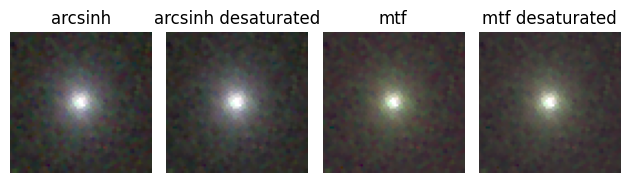

 20%|██        | 1/5 [00:16<01:05, 16.33s/it]

1 0.5317399713338831 0
23.579853572574923
len of asdf_cutout.cutouts = 3
Cutout Data Shape: (64, 64)
Cutout Original Position: (4776, 4054)
Cutout Position: (31, 31)


/tmp/ipykernel_1590/1176189917.py:313: RuntimeWarning: invalid value encountered in cast
  return (255 * im).astype(np.uint8)


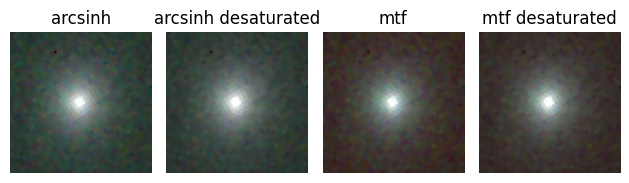

 40%|████      | 2/5 [00:26<00:37, 12.48s/it]

1 0.9614466607408345 0
len of asdf_cutout.cutouts = 3
Cutout Data Shape: (118, 118)
Cutout Original Position: (2657, 1066)
Cutout Position: (59, 58)


/tmp/ipykernel_1590/1176189917.py:313: RuntimeWarning: invalid value encountered in cast
  return (255 * im).astype(np.uint8)


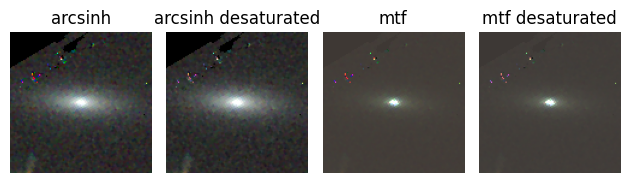

 60%|██████    | 3/5 [01:14<00:57, 28.65s/it]

1 0.6942666545098434 0
len of asdf_cutout.cutouts = 3
Cutout Data Shape: (84, 84)
Cutout Original Position: (3749, 1080)
Cutout Position: (42, 42)


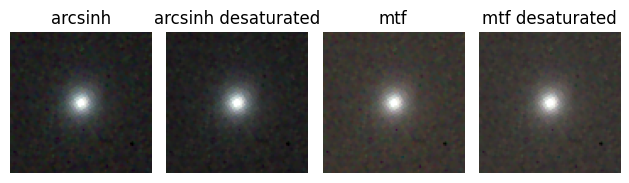

 80%|████████  | 4/5 [01:49<00:31, 31.51s/it]

1 0.8513893974455026 0
len of asdf_cutout.cutouts = 3
Cutout Data Shape: (98, 98)
Cutout Original Position: (3970, 1928)
Cutout Position: (49, 48)


/tmp/ipykernel_1590/1176189917.py:313: RuntimeWarning: invalid value encountered in cast
  return (255 * im).astype(np.uint8)


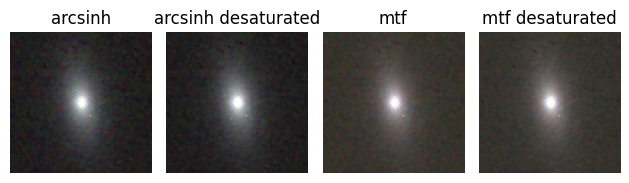

100%|██████████| 5/5 [02:23<00:00, 28.71s/it]


In [37]:
# # create cutouts of each object in query results...
cutout_size_phys = 5 #arcsec
pixel_scale_ = 0.11 #arcsec
# cutout_size_ = [int(cutout_size_phys/pixel_scale_),int(cutout_size_phys/pixel_scale_)] #pixels
# cutout_size_ = [100,100] #pixels
# print('cutout size = ', cutout_size_)

# for src_i in range(len(catalog_df)):
for src_i in trange(200):
    id_str = cat_df['id_str'][src_i]
    kron_abmag = cat_df[f'KronABmag_{bands[0]}'][src_i]
    kron_radius = cat_df[f'kron_radius_{bands[0]}'][src_i]/pixel_scale_
    kron_radius_50 = cat_df[f'kron_radius_flux50_{bands[0]}'][src_i]/pixel_scale_

    if kron_abmag <=17:
        fb = 2
    else:
        fb=1
    fr = pow((kron_radius/kron_radius_50), 0.4)
    fm = max(0, kron_abmag-22)
    print(fb, fr, fm)
    
    cutout_radius = fb*((50*kron_radius*fr)-(7*fm)) #pixels
    
    if cutout_radius < 32:
        print(cutout_radius)
        cutout_radius = 32
    
    # cutout_size_ = [int(cutout_size_phys/pixel_scale_),int(cutout_size_phys/pixel_scale_)] #pixels
    cutout_size_ = [2*int(cutout_radius),2*int(cutout_radius)] #pixels
    im_cut, scales_ = create_image_cutout_test([cat_df[f'asdf_loc_{bands[0]}'][src_i], cat_df[f'asdf_loc_{bands[1]}'][src_i], cat_df[f'asdf_loc_{bands[2]}'][src_i]], cutout_size_, [cat_df['RA'][src_i], cat_df['DEC'][src_i]], display_cut=False, display_full=False)
    cutouts_ = im_cut
    
    # If any of the bands is just 0's, don't run code
    if cutouts_[0].data.max()== 0 or cutouts_[1].data.max() == 0 or cutouts_[2].data.max() == 0:
        print('Wrong')
    f1_, f2_, f3_ = cutouts_[0].data, cutouts_[1].data, cutouts_[2].data

    
    # Step 2: make arsinh and mtf rgbs
    # try:
    q_ = [2.0/(5*np.nanmedian(f1_)),2.0/(5.0*np.nanmedian(f2_)),2.0/(5*np.nanmedian(f3_))]
    # print(q_)
    rgb_arcsinh = make_arcsinh_rgb(f1_, f2_, f3_, q=q_, weights = None).astype(np.uint8)

    
    means_ = [0.27, 0.25, 0.23, 0.25]
    # means_ = [0.2, 0.2, 0.2, 0.2]
    rgb_mtf = make_mtf_rgb(f1_, f2_, f3_, means=means_, weights = None).astype(np.uint8)

    # Step 3: desaturate
    rgb_arcsinh_desaturated = desaturate(rgb_arcsinh)
    rgb_mtf_desaturated = desaturate(rgb_mtf)
    
    # Step 4: visualise
    # Visualize_scalings([rgb_arcsinh, rgb_arcsinh_desaturated, rgb_mtf, rgb_mtf_desaturated], Labels=['arcsinh', 'arcsinh desaturated', 'mtf', 'mtf desaturated'])

    # except:
        # print('Failed to make image!')

    # Step 5: Save
    images = [rgb_arcsinh, rgb_arcsinh_desaturated, rgb_mtf, rgb_mtf_desaturated]
    suffix = ['arcsinh','arcsinh_desaturated','mtf','mtf_desaturated']

    for i,image in enumerate(images):
        # Use PIL Image
        output_file = f'{colour_cutout_save_dir}/{id_str}.png'
        img = Image.fromarray(image, mode='RGB')

        # Make sure to overwrite! Delete png file if there is already one there
        if os.path.isfile(output_file):
            os.remove(output_file)
            
        # Save
        img.save(output_file, format='PNG')
   
